import libraries

In [1]:
from langgraph.graph import START, END, StateGraph
from typing import TypedDict
from IPython.display import Image, display
from langchain_groq import ChatGroq

In [2]:
class BlogState(TypedDict):
    title:str
    outline:str
    blog:str

In [3]:
model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct")

In [4]:
def create_outline(state:BlogState):
    title = state['title']
    prompt = f"Generate an outline for blog post on the given title-{title}"
    outline = model.invoke(prompt)
    state['outline']=outline
    return state

In [21]:
def create_blogpost(state:BlogState):
    title = state['title']
    outline=state['outline']
    prompt = f"Generate a blog post on the basis of given title-{title} and outline-{outline}"
    blog = model.invoke(prompt)
    state['blog']=blog
    return state

In [23]:
graph = StateGraph(BlogState)

In [24]:
graph.add_node("Create_Outline",create_outline)
graph.add_node("Create_Blog",create_blogpost)

In [25]:
graph.add_edge(START,"Create_Outline")
graph.add_edge("Create_Outline","Create_Blog")
graph.add_edge("Create_Blog",END)

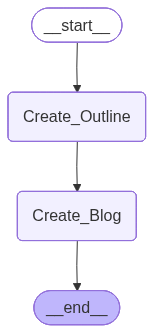

In [26]:
workflow = graph.compile()
Image(workflow.get_graph().draw_mermaid_png())

In [27]:
initial_state={"title":"Rise of AI"}
final_state= workflow.invoke(initial_state)
print(final_state)

{'title': 'Rise of AI', 'outline': AIMessage(content='Here is a suggested outline for a blog post on the title "Rise of AI":\n\n**Title:** The Rise of AI: Understanding the Future of Artificial Intelligence\n\n**I. Introduction**\n\n* Brief overview of Artificial Intelligence (AI) and its growing presence in our lives\n* Importance of discussing the rise of AI and its implications\n* Thesis statement: The rapid advancement of AI is transforming industries, revolutionizing the way we live and work, and redefining the future of humanity.\n\n**II. A Brief History of AI**\n\n* Early beginnings of AI: Dartmouth Summer Research Project on Artificial Intelligence (1956)\n* AI winter: reasons for the decline in AI research and funding (1970s-1980s)\n* Resurgence of AI: advances in machine learning, deep learning, and big data (1990s-2000s)\n\n**III. Current State of AI**\n\n* Definition of AI and its subfields (Machine Learning, Natural Language Processing, Computer Vision, etc.)\n* Examples o

In [30]:
print(final_state["blog"])

content='**The Rise of AI: Understanding the Future of Artificial Intelligence**\n\n**I. Introduction**\n\nArtificial Intelligence (AI) has become an integral part of our lives, transforming the way we live, work, and interact with technology. From virtual assistants like Siri and Alexa to self-driving cars and personalized medicine, AI is increasingly influencing various aspects of our daily lives. As AI continues to advance and become more pervasive, it is essential to discuss its rise and implications. In this blog post, we will explore the history of AI, its current state, rapid growth, impact on industries and society, and the opportunities and challenges it presents. The rapid advancement of AI is transforming industries, revolutionizing the way we live and work, and redefining the future of humanity.\n\n**II. A Brief History of AI**\n\nThe concept of AI dates back to the 1950s, when computer scientists began exploring ways to create intelligent machines. The Dartmouth Summer Res